# Vision-Based Gesture-to-Speech Translation for Sign Language

Python version: 3.12.6
Downloading dependencies.

In [2]:
%load_ext autoreload
%autoreload 2

%pip install torch torchvision kagglehub opencv-python tensorflow tensorflow.keras

# pytorch
import torch

# kaggle (for downloading datasets) and dataset manage
import kagglehub as kh
import os

Note: you may need to restart the kernel to use updated packages.


In [3]:
# dataset download
lis_path = kh.dataset_download("nicholasnisopoli/lisdataset")
asl_path = kh.dataset_download("grassknoted/asl-alphabet")
print("Italian Sing Language dataset path:", lis_path)
print("American Sign Language dataset path:", asl_path)
lis_dataset = os.path.join(lis_path, "LIS-fingerspelling-dataset")
asl_dataset = os.path.join(asl_path, "asl_alphabet_train/asl_alphabet_train")

Italian Sing Language dataset path: /Users/anna/.cache/kagglehub/datasets/nicholasnisopoli/lisdataset/versions/1
American Sign Language dataset path: /Users/anna/.cache/kagglehub/datasets/grassknoted/asl-alphabet/versions/1


In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


## LIS model

In [5]:
from train import train_and_save
from plotter import plot_loss, plot_acc

from dataclasses import dataclass

@dataclass
class TrainConfig:
    train_threshold: float = 0.85
    epochs: int = 25
    batch_size: int = 32
    learning_rate: float = 0.01
    
    
config = TrainConfig()

In [6]:
from model import SignLanguageCNN
path_params = "models/lis_model.pth"

# If you want to save the paramenters, change output_path with path_params
lis_history = train_and_save(dataset=lis_dataset, model_class=SignLanguageCNN, config=config, device=device, output_path=None)

Epoch 01/25 | train_loss=3.0911, train_acc=0.0442 | test_loss=3.0879, test_acc=0.0512
Epoch 02/25 | train_loss=3.0851, train_acc=0.0528 | test_loss=3.0792, test_acc=0.0614
Epoch 03/25 | train_loss=3.0653, train_acc=0.1167 | test_loss=3.0284, test_acc=0.2231
Epoch 04/25 | train_loss=2.7010, train_acc=0.1989 | test_loss=2.3907, test_acc=0.2682
Epoch 05/25 | train_loss=1.9074, train_acc=0.3746 | test_loss=1.9604, test_acc=0.3173
Epoch 06/25 | train_loss=1.4852, train_acc=0.5082 | test_loss=1.3911, test_acc=0.5118
Epoch 07/25 | train_loss=1.1884, train_acc=0.5975 | test_loss=1.3336, test_acc=0.5353
Epoch 08/25 | train_loss=0.9290, train_acc=0.6870 | test_loss=1.0961, test_acc=0.6090
Epoch 09/25 | train_loss=0.7123, train_acc=0.7555 | test_loss=0.7847, test_acc=0.7359
Epoch 10/25 | train_loss=0.5340, train_acc=0.8154 | test_loss=0.6013, test_acc=0.7728
Epoch 11/25 | train_loss=0.3947, train_acc=0.8686 | test_loss=0.4798, test_acc=0.8383
Epoch 12/25 | train_loss=0.2902, train_acc=0.9041 | te

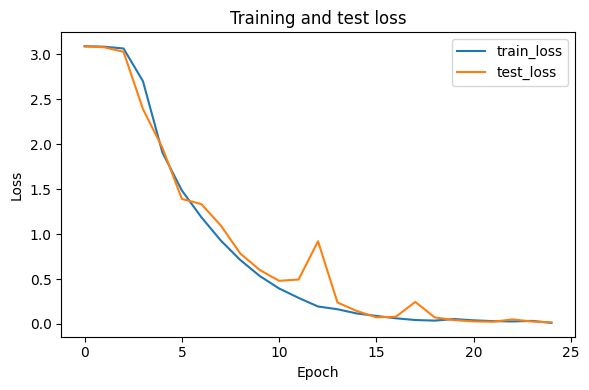

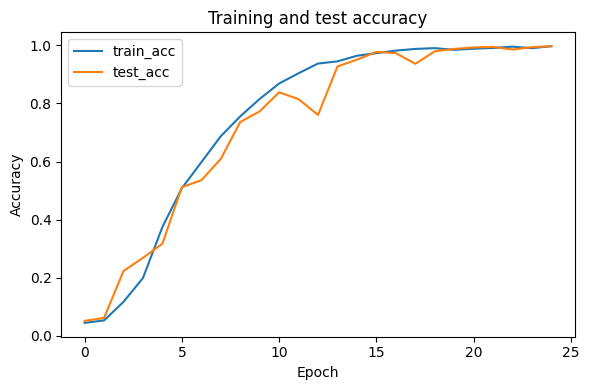

In [7]:
plot_loss(lis_history)
plot_acc(lis_history)

## ASL model

In [8]:
path_params = "models/asl_model.pth"

# If you want to save the paramenters, change output_path with path_params
asl_history = train_and_save(dataset=asl_dataset, model_class=SignLanguageCNN, config=config, device=device, output_path=None)

Epoch 01/25 | train_loss=3.1095, train_acc=0.1119 | test_loss=2.3767, test_acc=0.2717
Epoch 02/25 | train_loss=1.5613, train_acc=0.4969 | test_loss=0.9739, test_acc=0.6624
Epoch 03/25 | train_loss=0.6418, train_acc=0.7774 | test_loss=0.5048, test_acc=0.8153
Epoch 04/25 | train_loss=0.3386, train_acc=0.8829 | test_loss=0.3433, test_acc=0.8826
Epoch 05/25 | train_loss=0.2122, train_acc=0.9271 | test_loss=0.2706, test_acc=0.9020
Epoch 06/25 | train_loss=0.1454, train_acc=0.9516 | test_loss=0.2022, test_acc=0.9306
Epoch 07/25 | train_loss=0.0984, train_acc=0.9674 | test_loss=0.1638, test_acc=0.9441
Epoch 08/25 | train_loss=0.0796, train_acc=0.9736 | test_loss=0.1103, test_acc=0.9634
Epoch 09/25 | train_loss=0.0638, train_acc=0.9783 | test_loss=0.1127, test_acc=0.9623
Epoch 10/25 | train_loss=0.0589, train_acc=0.9818 | test_loss=0.0755, test_acc=0.9757
Epoch 11/25 | train_loss=0.0398, train_acc=0.9874 | test_loss=0.0730, test_acc=0.9767
Epoch 12/25 | train_loss=0.0329, train_acc=0.9897 | te

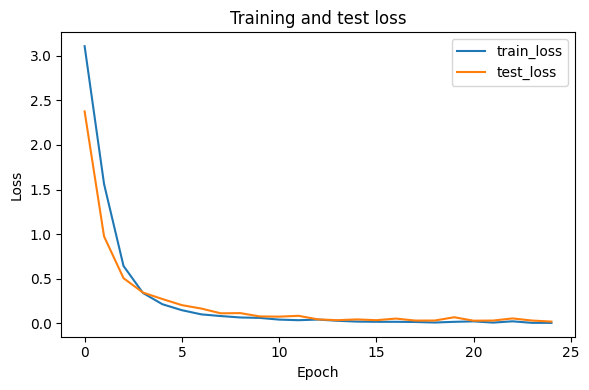

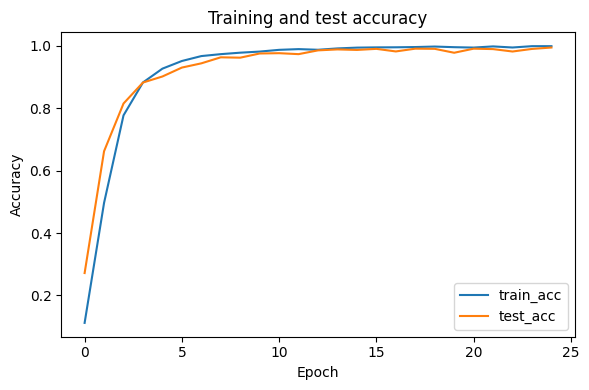

In [9]:
plot_loss(asl_history)
plot_acc(asl_history)

## ResNET50

In [10]:
from ResNet import Bottleneck, ResNet, ResNet50
path_params = "models/resnet_model.pth"

# If you want to save the paramenters, change output_path with path_params
resnet_history = train_and_save(dataset=lis_dataset, model_class=ResNet50, config=config, device=device, output_path="resnet_lis_model")

Epoch 01/25 | train_loss=2.5634, train_acc=0.2097 | test_loss=1.9009, test_acc=0.3900
Epoch 02/25 | train_loss=0.7768, train_acc=0.7522 | test_loss=0.9737, test_acc=0.6244
Epoch 03/25 | train_loss=0.2870, train_acc=0.9209 | test_loss=1.0068, test_acc=0.6776
Epoch 04/25 | train_loss=0.1204, train_acc=0.9751 | test_loss=5.1187, test_acc=0.3132
Epoch 05/25 | train_loss=0.0568, train_acc=0.9916 | test_loss=0.0748, test_acc=0.9836
Epoch 06/25 | train_loss=0.0169, train_acc=0.9993 | test_loss=0.0134, test_acc=0.9980
Epoch 07/25 | train_loss=0.0112, train_acc=0.9998 | test_loss=0.0224, test_acc=0.9969
Epoch 08/25 | train_loss=0.0089, train_acc=0.9998 | test_loss=0.0101, test_acc=1.0000
Epoch 09/25 | train_loss=0.0077, train_acc=0.9998 | test_loss=0.0394, test_acc=0.9959
Epoch 10/25 | train_loss=0.0085, train_acc=0.9989 | test_loss=0.4709, test_acc=0.8772
Epoch 11/25 | train_loss=0.0095, train_acc=0.9994 | test_loss=0.0471, test_acc=0.9867
Epoch 12/25 | train_loss=0.0056, train_acc=0.9998 | te

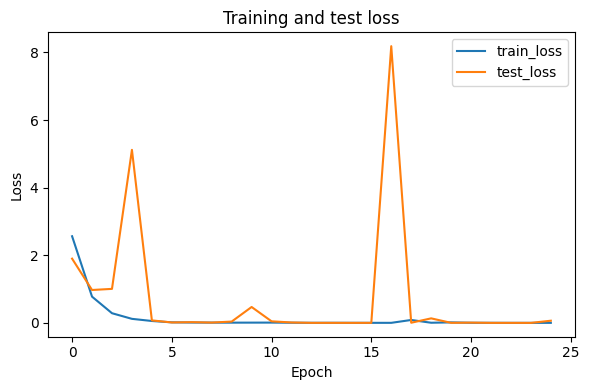

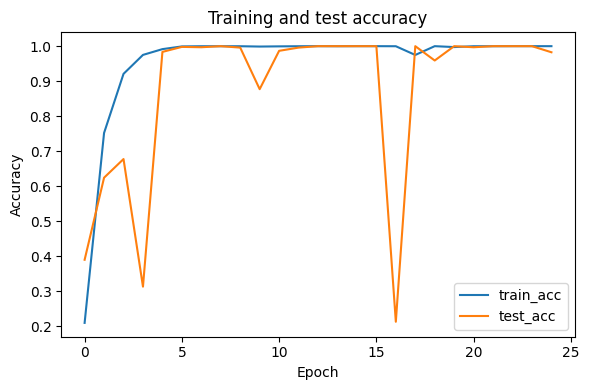

In [11]:
plot_loss(resnet_history)
plot_acc(resnet_history)

## MobileNetV2

In [12]:
from mobilenetv2 import MobileNetV2
lis_history = train_and_save(dataset=lis_dataset, model_class=MobileNetV2, config=config, device=device, output_path="mnv2_lis_model.pth")

NameError: name 'cv2' is not defined

In [ ]:
plot_loss(resnet_history)
plot_acc(resnet_history)